# Tarea 1 – Parte 2: Modelado y clasificación de titulares

- **Estudiante:** *(tu nombre y @usuario_github)*
- **Medio:** El Comercio · **Categorías:** `politica`, `economia`, `deportes`, `ciencia_tecnologia`
- **Entorno:** Google Colab con GPU T4 (*Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*)

**Qué hace este cuaderno, en orden**

1. Carga `datos/noticias.csv` y hace la **división estratificada 70/15/15** (`random_state=42`).
2. **Zero-shot** sobre 40 titulares del conjunto de prueba (sin entrenar nada).
3. **Etiquetado débil con un LLM** (Gemini) + **auditoría humana de 20 casos** → `datos/etiquetas_llm.csv`.
4. **Fine-tuning** de `distilbert-base-multilingual-cased` con `Trainer` (3 épocas).
5. **Evaluación en test**: accuracy, F1 macro, matriz de confusión y reflexión por categoría.
6. **Tabla comparativa** y justificación.

**Antes de ejecutar:** en Colab, ícono de la llave (Secretos) → agrega `GEMINI_API_KEY` y activa «Acceso desde el cuaderno». Opcional: `HF_TOKEN` si quieres subir el modelo a Hugging Face.

In [1]:
%pip install -q transformers datasets accelerate scikit-learn seaborn google-genai huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, os, subprocess, time, warnings
from getpass import getpass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
SEED = 42

# Si estamos en Colab, descargamos el repositorio (los datos ya están subidos a GitHub).
if not os.path.exists("datos/noticias.csv"):
    if not os.path.exists("Cursos"):
        subprocess.run(["git", "clone", "https://github.com/gabriela-pozo/Cursos.git"], check=True)
    os.chdir("Cursos/tarea_1")
os.makedirs("modelo", exist_ok=True)

def leer_secreto(nombre):
    """Busca la clave en los Secretos de Colab, luego en variables de entorno; si no, la pide."""
    try:
        from google.colab import userdata
        return userdata.get(nombre)
    except Exception:
        return os.getenv(nombre) or getpass(f"{nombre}: ")

print("GPU disponible:", torch.cuda.is_available(), "| carpeta:", os.getcwd())

GPU disponible: False | carpeta: C:\Users\Asus\Documents\Cursos\tarea_1


## 1. Datos y división train / validación / test

**Teoría.** Un modelo se evalúa con datos que **nunca vio**. Por eso dividimos en tres:

| Conjunto | Para qué sirve | Tamaño |
|---|---|---|
| **train** | el modelo aprende de aquí | 70 % |
| **validación** | elegir época/hiperparámetros durante el entrenamiento | 15 % |
| **test** | nota final, se usa **una sola vez** al final | 15 % |

- **Estratificada:** cada conjunto mantiene la misma proporción de categorías que el total (si no, el test podría quedar sin deportes, por ejemplo).
- **`random_state=42`:** fija el azar para que cualquiera que repita el cuaderno obtenga la misma división.
- **Fuga de datos (*leakage*):** si un titular casi idéntico está en train y en test, el modelo «hace trampa». Por eso en la Parte 1 se eliminaron los duplicados; aquí lo comprobamos otra vez.

In [3]:
ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
ID2LABEL = dict(enumerate(ETIQUETAS))
LABEL2ID = {e: i for i, e in ID2LABEL.items()}

df = pd.read_csv("datos/noticias.csv").fillna({"bajada": ""})
assert set(df["etiqueta"]) == set(ETIQUETAS), "hay etiquetas fuera de las 4 categorías"
df["y"] = df["etiqueta"].map(LABEL2ID)
print("Total:", df.shape)
df["etiqueta"].value_counts()

Total: (385, 8)


etiqueta
deportes              101
politica               96
ciencia_tecnologia     95
economia               93
Name: count, dtype: int64

In [4]:
train, temp = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["etiqueta"], random_state=SEED)
train, val, test = (x.reset_index(drop=True) for x in (train, val, test))

# Comprobaciones: sin solapes por URL ni por titular normalizado.
norm = lambda s: s.str.lower().str.replace(r"\W+", " ", regex=True).str.strip()
for a, b, nombre in [(train, val, "train-val"), (train, test, "train-test"), (val, test, "val-test")]:
    assert not set(a["url"]) & set(b["url"]), f"URL repetida entre {nombre}"
    assert not set(norm(a["titular"])) & set(norm(b["titular"])), f"titular repetido entre {nombre}"

division = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")], ignore_index=True)
division[["url", "split"]].to_csv("datos/split.csv", index=False)
pd.crosstab(division["etiqueta"], division["split"], margins=True)

split,test,train,val,All
etiqueta,,,,
ciencia_tecnologia,15,66,14,95
deportes,15,71,15,101
economia,14,65,14,93
politica,14,67,15,96
All,58,269,58,385


## 2. Métricas: accuracy y F1 macro

- **Accuracy** = aciertos / total. Es fácil de leer, pero engaña si las clases están desbalanceadas.
- **Precisión** (de lo que dije «deportes», ¿cuánto lo era?) y **recall** (de todo lo que era deportes, ¿cuánto encontré?).
- **F1** = media armónica de precisión y recall para **una** clase. **F1 macro** = promedio simple de los F1 de las 4 clases: todas pesan igual, y por eso es la métrica oficial de la tarea.

In [5]:
def metricas(y_real, y_pred):
    return {"accuracy": accuracy_score(y_real, y_pred),
            "f1_macro": f1_score(y_real, y_pred, average="macro")}

## 3. Zero-shot (sin entrenar)

**Teoría.** Un modelo *zero-shot* clasifica en categorías que nunca vio etiquetadas. Se apoya en un modelo de **inferencia de lenguaje natural (NLI)**: para cada categoría arma una hipótesis («Este titular trata sobre *deportes*») y pregunta si el titular la implica. La categoría con mayor probabilidad gana.

Modelo: `joeddav/xlm-roberta-large-xnli` (multilingüe, incluye español). Lo probamos sobre **40 titulares del conjunto de prueba** (10 por categoría, semilla 42).

In [6]:
from transformers import pipeline

NOMBRES_ES = {"politica": "política", "economia": "economía", "deportes": "deportes",
              "ciencia_tecnologia": "ciencia y tecnología"}
ES2ETIQ = {v: k for k, v in NOMBRES_ES.items()}

muestra40 = pd.concat([g.sample(min(len(g), 10), random_state=SEED) for _, g in test.groupby("etiqueta")]).reset_index(drop=True)
print("Titulares en la muestra:", len(muestra40))

t0 = time.time()
zs = pipeline("zero-shot-classification", model="joeddav/xlm-roberta-large-xnli",
              device=0 if torch.cuda.is_available() else -1)
salidas = zs(list(muestra40["titular"]), candidate_labels=list(NOMBRES_ES.values()),
             hypothesis_template="Este titular trata sobre {}.", batch_size=8)
muestra40["pred_zs"] = [ES2ETIQ[s["labels"][0]] for s in salidas]
tiempo_zs = time.time() - t0

res_zs = metricas(muestra40["etiqueta"], muestra40["pred_zs"])
print(f"Zero-shot (40 titulares) -> accuracy {res_zs['accuracy']:.3f} | F1 macro {res_zs['f1_macro']:.3f} | {tiempo_zs:.0f} s")
muestra40.loc[muestra40["etiqueta"] != muestra40["pred_zs"], ["titular", "etiqueta", "pred_zs"]]

Titulares en la muestra: 40



Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]


Loading weights:   4%|▍         | 17/393 [00:00<00:02, 156.63it/s]


Loading weights:   8%|▊         | 33/393 [00:00<00:04, 85.54it/s] 


Loading weights:  11%|█         | 44/393 [00:00<00:04, 74.40it/s]

...


Loading weights:  21%|██▏       | 84/393 [00:01<00:04, 68.61it/s]


Loading weights: 100%|██████████| 393/393 [00:01<00:00, 353.00it/s]


[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Zero-shot (40 titulares) -> accuracy 0.825 | F1 macro 0.820 | 23 s


,titular,etiqueta,pred_zs
0,“Ace Combat 8: Wings of Theve” eleva la franqu...,ciencia_tecnologia,deportes
2,Finlandia frena la construcción de dos centros...,ciencia_tecnologia,politica
4,Estafas digitales contra adultos mayores: seis...,ciencia_tecnologia,economia
15,El furioso “Que se dedique a administrar” de G...,deportes,politica
22,"Mario Gonzales, CEO de Luz del Sur: “Nuestra i...",economia,ciencia_tecnologia
26,"El dólar abre en S/3,44 ante retroceso de la d...",economia,deportes
28,"De consultar saldos a delegar operaciones, ¿có...",economia,ciencia_tecnologia


## 4. Etiquetado débil con un LLM y auditoría humana

**Teoría.** En la práctica etiquetar a mano miles de textos es caro. Un LLM puede dar etiquetas **rápidas y baratas pero imperfectas**: se llaman *etiquetas débiles* (*weak labels*). Por eso nunca se confía a ciegas: se **audita una muestra** a mano y se mide el acuerdo.

Aquí el LLM (Gemini) etiqueta **los 385 titulares** usando solo el titular, en lotes de 50 para ahorrar llamadas (la cuota gratuita es de pocas peticiones al día). El avance se guarda en `datos/etiquetas_llm_progreso.csv`: si se corta, al volver a ejecutar la celda solo se repiten los lotes pendientes. Las etiquetas de entrenamiento del modelo siguen siendo las de la Parte 1 (sección del medio); el LLM sirve para **contrastarlas** y para la auditoría. Guardamos `datos/etiquetas_llm.csv`.

> La clave se lee de los Secretos de Colab (`GEMINI_API_KEY`). **Nunca la escribas en el cuaderno.** Si el nombre del modelo ya no existe, revisa los vigentes en https://ai.google.dev/gemini-api/docs/models y cambia `MODELO_LLM`.

In [7]:
from google import genai

MODELO_LLM = "gemini-3.5-flash-lite"
RUTA_LLM = "datos/etiquetas_llm.csv"
RUTA_PROGRESO = "datos/etiquetas_llm_progreso.csv"  # lotes ya etiquetados: si la celda se corta, se reanuda desde aquí
TAM_LOTE = 50  # la cuota gratuita es de pocas peticiones al día por modelo: lotes grandes = menos peticiones

PROMPT = """Eres un editor de un diario peruano. Clasifica cada titular en UNA sola categoría:
- politica: gobierno, Congreso, elecciones, partidos, justicia y temas políticos
- economia: dinero, precios, empresas, empleo, bolsa, dólar, impuestos
- deportes: fútbol, otros deportes, competiciones, deportistas
- ciencia_tecnologia: ciencia, tecnología, internet, celulares, IA, espacio, salud-ciencia

Responde SOLO con un JSON válido: una lista de objetos {"id": <número>, "etiqueta": "<categoría>", "confianza": <0 a 1>}.

Titulares:
"""

def etiquetar_lote(cliente, titulares, intentos=3):
    """Devuelve ([(etiqueta, confianza), ...], modelo que respondió), o None si el lote falla en todos los intentos."""
    texto = PROMPT + "\n".join(f"{i}. {t}" for i, t in enumerate(titulares))
    for n in range(intentos):
        try:
            r = cliente.models.generate_content(model=MODELO_LLM, contents=texto,
                                                config={"response_mime_type": "application/json", "temperature": 0})
            respuesta = json.loads(r.text)
            ids = sorted(int(d["id"]) for d in respuesta)
            if ids != list(range(len(titulares))):  # cada titular del lote debe venir exactamente una vez
                raise ValueError(f"llegaron {len(ids)} elementos con IDs inesperados (se esperaban 0..{len(titulares) - 1})")
            datos = {int(d["id"]): d for d in respuesta}
            return [(datos[i]["etiqueta"], float(datos[i]["confianza"])) for i in range(len(titulares))], r.model_version
        except Exception as e:
            print(f"  intento {n + 1} falló: {str(e)[:300]}")
            time.sleep(10 * (n + 1))
    return None

def comprobar_etiquetado(llm, consecuencia):
    """Más de 5 % de etiquetas inválidas indica que algo falló (modelo, clave, cuota): se lanza error."""
    prop_invalidas = (~llm["etiqueta_llm"].isin(ETIQUETAS)).mean()
    if prop_invalidas > 0.05:
        raise RuntimeError(f"Etiquetado LLM fallido: {prop_invalidas:.1%} de etiquetas inválidas o 'sin_respuesta' "
                           f"(máximo 5 %). {consecuencia} Revisa MODELO_LLM, la clave y la cuota.")

if os.path.exists(RUTA_LLM):
    llm = pd.read_csv(RUTA_LLM)
    comprobar_etiquetado(llm, f"No se usa {RUTA_LLM}: renómbralo para volver a etiquetar.")
    print("Se reutiliza", RUTA_LLM, llm.shape)
else:
    if os.path.exists(RUTA_PROGRESO):
        progreso = pd.read_csv(RUTA_PROGRESO)
    else:
        progreso = pd.DataFrame(columns=["titular", "etiqueta_llm", "confianza", "modelo_pedido", "modelo_llm", "fecha"])
    otros = set(progreso["modelo_pedido"]) - {MODELO_LLM}
    if otros:
        raise RuntimeError(f"{RUTA_PROGRESO} se hizo con {otros}, no con {MODELO_LLM}: usa el mismo modelo o renombra el archivo.")

    unicos = list(dict.fromkeys(df["titular"]))
    pendientes = [t for t in unicos if t not in set(progreso["titular"])]
    print(f"Ya etiquetados: {len(unicos) - len(pendientes)} | pendientes: {len(pendientes)}")
    cliente = genai.Client(api_key=leer_secreto("GEMINI_API_KEY"))
    sin_etiquetar = 0
    for ini in range(0, len(pendientes), TAM_LOTE):
        lote = pendientes[ini:ini + TAM_LOTE]
        resultado = etiquetar_lote(cliente, lote)
        if resultado is None:  # no se guarda: al volver a ejecutar la celda se repite solo este lote
            sin_etiquetar += len(lote)
            print(f"  lote {ini}-{ini + len(lote) - 1} falló")
            continue
        etiquetas, modelo_resp = resultado
        otros = set(progreso["modelo_llm"]) - {modelo_resp}
        if otros:
            raise RuntimeError(f"Respondió {modelo_resp}, pero el progreso se hizo con {otros}: no se mezclan modelos.")
        nuevas = pd.DataFrame([{"titular": t, "etiqueta_llm": et, "confianza": conf, "modelo_pedido": MODELO_LLM,
                                "modelo_llm": modelo_resp, "fecha": time.strftime("%Y-%m-%d")}
                               for t, (et, conf) in zip(lote, etiquetas)])
        progreso = pd.concat([progreso, nuevas], ignore_index=True)
        progreso.to_csv(RUTA_PROGRESO, index=False)
        print(f"  {len(progreso)}/{len(unicos)} ({modelo_resp})")
        time.sleep(4)
    if sin_etiquetar:
        raise RuntimeError(f"{sin_etiquetar} titulares sin etiquetar. Vuelve a ejecutar la celda: solo se repiten los lotes pendientes.")

    # Una fila por titular de df y en su orden: la muestra de la auditoría depende de ese orden.
    llm = df[["titular"]].merge(progreso.drop_duplicates("titular"), on="titular", how="left")
    comprobar_etiquetado(llm, f"No se guardó {RUTA_LLM}.")  # solo se guarda si el etiquetado es válido
    llm.to_csv(RUTA_LLM, index=False)

print("Etiquetas inválidas o sin respuesta:", (~llm["etiqueta_llm"].isin(ETIQUETAS)).sum())
llm["etiqueta_llm"].value_counts()

Ya etiquetados: 0 | pendientes: 385


  50/385 (gemini-3.5-flash-lite)


  100/385 (gemini-3.5-flash-lite)


  150/385 (gemini-3.5-flash-lite)


  200/385 (gemini-3.5-flash-lite)


...

  300/385 (gemini-3.5-flash-lite)


  350/385 (gemini-3.5-flash-lite)


  385/385 (gemini-3.5-flash-lite)


Etiquetas inválidas o sin respuesta: 0


etiqueta_llm
politica              104
deportes              100
ciencia_tecnologia     94
economia               87
Name: count, dtype: int64

In [8]:
# ¿Cuánto coincide el LLM con las etiquetas de la Parte 1 (sección del medio)?
comp = df[["titular", "etiqueta"]].merge(llm, on="titular", how="left")
acuerdo_total = (comp["etiqueta"] == comp["etiqueta_llm"]).mean()
print(f"Acuerdo LLM vs sección del medio (385 titulares): {acuerdo_total:.1%}")

en_test = comp[comp["titular"].isin(test["titular"])]
res_llm_test = metricas(en_test["etiqueta"], en_test["etiqueta_llm"].where(en_test["etiqueta_llm"].isin(ETIQUETAS), "politica"))
print(f"LLM sobre el test -> accuracy {res_llm_test['accuracy']:.3f} | F1 macro {res_llm_test['f1_macro']:.3f}")

# Desacuerdos: ¿quién tiene razón, el LLM o la sección?
comp.loc[comp["etiqueta"] != comp["etiqueta_llm"], ["titular", "etiqueta", "etiqueta_llm", "confianza"]].head(15)

Acuerdo LLM vs sección del medio (385 titulares): 91.9%
LLM sobre el test -> accuracy 0.914 | F1 macro 0.913


,titular,etiqueta,etiqueta_llm,confianza
5,Viceministra de Minas: “Estamos estableciendo ...,politica,economia,0.8
8,Proyecto de Ley MAPE del gobierno propone que ...,politica,economia,0.85
32,Rodrigo Paz visitará el Perú en noviembre para...,politica,economia,0.8
34,Ley MAPE: Minem prevé presentar propuesta este...,politica,economia,0.85
62,Unión Europea y Minem acuerdan creación de mes...,politica,economia,0.9
72,Ministro Guillermo Shinno presenta propuesta d...,politica,economia,0.9
99,SwissCham Summit 2026: Líderes empresariales s...,economia,ciencia_tecnologia,0.9
109,"De consultar saldos a delegar operaciones, ¿có...",economia,ciencia_tecnologia,0.95
113,IA y Sandbox regulatorio,economia,ciencia_tecnologia,0.9
115,"Justin Trudeau, exprimer ministro de Canadá, s...",economia,politica,0.8


### Auditoría humana de 20 titulares al azar

Haz la auditoría **a ciegas** (sin ver la etiqueta del LLM) para no sesgarte:

1. Ejecuta la celda siguiente: te muestra 20 titulares numerados.
2. Léelos y escribe **tú** la categoría de cada uno en la lista `MIS_ETIQUETAS` (de la celda que sigue), en el mismo orden. Valores permitidos: `politica`, `economia`, `deportes`, `ciencia_tecnologia`.
3. Ejecuta la última celda: calcula el acuerdo `xx/20` y te muestra los casos donde difieres.

In [4]:
import pandas as pd

leer = pd.read_csv("datos/noticias.csv")[["titular"]].sample(20, random_state=42).reset_index(drop=True)
for i, t in enumerate(leer["titular"]):
    print(f"{i:>2}. {t}")

 0. La Ruta del Pejerrey 2026 será el 12 de diciembre: carrera solidaria unirá Miraflores y La Punta a beneficio de niños con cáncer
 1. ¡Oro para Perú! Aleska Musiris conquista el Panamericano de Esquí Acuático Sub-14
 2. Así puedes mejorar la señal WiFi en tu casa: apagando estos dispositivos - Clone
 3. ¿Dejas siempre encendido el Bluetooth de tu celular? Por qué expertos recomiendan apagarlo
 4. Miguel Torres: “Nos unimos en oración por la pronta recuperación del papa León XIV”
 5. TikTok anuncia la compra directa a marcas sin salir de la ‘app’ y un chatbot con IA que recomienda productos
 6. Jaime Delgado: “Pienso que deberíamos mantenernos en los 20 puntos aprobados por Diputados”
 7. Rextie se prepara para su primer salto internacional: ¿a qué mercados mira la fintech de cambio de dólares y otras divisas?
 8. Organización que gestiona Wikipedia denuncia actividad no autorizada de agentes de OpenAI
 9. ¡Por primera vez en el Clausura! Piero Cari será convocado para el duelo de Al

In [5]:
auditoria = llm.sample(20, random_state=SEED).reset_index(drop=True)
for i, t in enumerate(auditoria["titular"]):
    print(f"{i:>2}. {t}")

NameError: name 'llm' is not defined

In [11]:
MIS_ETIQUETAS = [
    "politica", "deportes", "ciencia_tecnologia", "ciencia_tecnologia", "politica",     # 0-4
    "ciencia_tecnologia", "politica", "ciencia_tecnologia", "ciencia_tecnologia", "deportes",   # 5-9
    "deportes", "ciencia_tecnologia", "deportes", "deportes", "economia",             # 10-14
    "economia", "economia", "ciencia_tecnologia", "politica", "deportes",             # 15-19
]

validas = [e in ETIQUETAS for e in MIS_ETIQUETAS]
if len(MIS_ETIQUETAS) != 20 or not all(validas):
    print("Aún faltan etiquetas o hay valores no permitidos. Revisa la lista.")
    acuerdo_20 = None
else:
    auditoria["etiqueta_humana"] = MIS_ETIQUETAS
    acuerdo_20 = int((auditoria["etiqueta_humana"] == auditoria["etiqueta_llm"]).sum())
    print(f"Acuerdo LLM-Humano: {acuerdo_20}/20")
    auditoria.loc[auditoria["etiqueta_humana"] != auditoria["etiqueta_llm"], ["titular", "etiqueta_humana", "etiqueta_llm", "confianza"]]

Acuerdo LLM-Humano: 16/20


**Tu análisis (escríbelo aquí, 3–4 líneas):** ¿En qué casos se equivocó el LLM? ¿Eran titulares ambiguos (por ejemplo, economía del deporte o política tecnológica)? ¿Tenía menos confianza en esos? ¿Confiarías en este etiquetado sin auditoría para entrenar un modelo?
**Auditoría humana (20 titulares): el LLM coincidió conmigo en 16 (80 %).** Los 4 desacuerdos no son errores claros del LLM, sino casos de frontera donde el titular combina dos temas:

- **Titular 0 (carrera solidaria «La Ruta del Pejerrey»):** yo puse `politica`, pensando en la iniciativa a favor de niños con cáncer; el LLM puso `deportes` (0.80). Visto después, deportes es más defendible porque el titular describe una carrera. Aquí el error fue mío. Mantengo 16/20 porque la auditoría fue a ciegas.
- **Titular 7 (Rextie, fintech de divisas):** yo `ciencia_tecnologia` por ser una fintech; el LLM `economia` (0.95). Es tecnología aplicada a finanzas: ambas son razonables.
- **Titular 11 (Indecopi e Interseguro, filtración de datos):** yo `ciencia_tecnologia` por la filtración; el LLM `economia` (0.80), probablemente por la aseguradora y el regulador. También mixto.
- **Titular 18 (Finlandia frena centros de datos de Google):** yo `politica`, entendiéndolo como una medida para frenar un daño ambiental; el LLM `ciencia_tecnologia` (0.90) por los centros de datos. Defendibles ambas.

**Patrón:** el LLM se guía por el tema nominal del titular (carrera, empresa, centros de datos) y yo por el contexto (iniciativa, fintech, medida). Su confianza fue alta (0.80 a 0.95) incluso en casos ambiguos, así que no sirve como señal de ambigüedad. Además, el LLM coincide con la sección de El Comercio en el 91.95 % de los 385 titulares, lo que sugiere que las etiquetas por sección son razonables, aunque con ruido en los temas mixtos.

## 5. Fine-tuning de DistilBERT multilingüe

**Teoría.**
- **Transformer preentrenado:** `distilbert-base-multilingual-cased` ya «sabe español» porque leyó millones de textos. No lo entrenamos desde cero.
- **Fine-tuning:** le pegamos una capa final de clasificación (4 salidas) y seguimos entrenando con **nuestros** titulares para que ajuste sus pesos a la tarea.
- **Tokenización:** el texto se parte en *tokens* (subpalabras) y se convierte en números; `max_length=64` basta para un titular.
- **Época:** una pasada completa por el train. Usamos **3**. Pocas épocas: no aprende; demasiadas: **sobreajusta** (memoriza el train y falla en datos nuevos). Por eso miramos la **validación** al final de cada época y nos quedamos con la mejor.
- **Batch size 16:** cuántos ejemplos procesa antes de actualizar los pesos. **Learning rate 5e-5:** qué tan grandes son esos ajustes.

In [12]:
from datasets import Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, set_seed)

set_seed(SEED)
NOMBRE_MODELO = "distilbert-base-multilingual-cased"
tokenizador = AutoTokenizer.from_pretrained(NOMBRE_MODELO)

def a_dataset(d):
    ds = Dataset.from_pandas(d[["titular", "y"]].rename(columns={"y": "label"}), preserve_index=False)
    return ds.map(lambda lote: tokenizador(lote["titular"], truncation=True, max_length=64), batched=True, remove_columns=["titular"])

ds_train, ds_val, ds_test = a_dataset(train), a_dataset(val), a_dataset(test)

modelo = AutoModelForSequenceClassification.from_pretrained(
    NOMBRE_MODELO, num_labels=len(ETIQUETAS), id2label=ID2LABEL, label2id=LABEL2ID)

def calcular_metricas(p):
    pred = np.argmax(p.predictions, axis=1)
    return metricas(p.label_ids, pred)

opciones = dict(output_dir="modelo/checkpoints", num_train_epochs=3, per_device_train_batch_size=16,
                per_device_eval_batch_size=32, learning_rate=5e-5, weight_decay=0.01,
                save_strategy="epoch", load_best_model_at_end=True, metric_for_best_model="f1_macro",
                save_total_limit=1, logging_steps=10, report_to="none", seed=SEED,
                fp16=torch.cuda.is_available())
try:
    args = TrainingArguments(eval_strategy="epoch", **opciones)
except TypeError:  # versiones antiguas de transformers
    args = TrainingArguments(evaluation_strategy="epoch", **opciones)

entrenador = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                     data_collator=DataCollatorWithPadding(tokenizador), compute_metrics=calcular_metricas)

t0 = time.time()
entrenador.train()
tiempo_ft = time.time() - t0
print(f"Entrenamiento: {tiempo_ft:.0f} s")


Map:   0%|          | 0/269 [00:00<?, ? examples/s]


Map: 100%|██████████| 269/269 [00:00<00:00, 6604.78 examples/s]


Map:   0%|          | 0/58 [00:00<?, ? examples/s]


Map: 100%|██████████| 58/58 [00:00<00:00, 4762.34 examples/s]


Map:   0%|          | 0/58 [00:00<?, ? examples/s]

...


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.46it/s]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.36it/s]


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.35it/s]

Entrenamiento: 79 s


In [13]:
# Curvas por época: ¿hay sobreajuste? (pérdida de train baja pero la de validación sube)
log = pd.DataFrame(entrenador.state.log_history)
ev = log.dropna(subset=["eval_f1_macro"])[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]
ev

,epoch,eval_loss,eval_accuracy,eval_f1_macro
1,1.0,0.833368,0.741379,0.699628
4,2.0,0.441805,0.931034,0.928602
7,3.0,0.388238,0.913793,0.910370


## 6. Evaluación final en test

Este es el único momento en que se usa el conjunto de prueba. Reporta **accuracy**, **F1 macro**, la **matriz de confusión** (filas = categoría real, columnas = predicha; la diagonal son los aciertos) y el desempeño por categoría.

In [14]:
pred_out = entrenador.predict(ds_test)
logits = pred_out.predictions
probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
test["pred_ft"] = [ID2LABEL[i] for i in logits.argmax(axis=1)]
test["prob_ft"] = probs.max(axis=1)

res_ft = metricas(test["y"], logits.argmax(axis=1))
print(f"Fine-tuning (test, {len(test)} titulares) -> accuracy {res_ft['accuracy']:.3f} | F1 macro {res_ft['f1_macro']:.3f}\n")
print(classification_report(test["etiqueta"], test["pred_ft"], labels=ETIQUETAS, digits=3, zero_division=0))

Fine-tuning (test, 58 titulares) -> accuracy 0.810 | F1 macro 0.784

                    precision    recall  f1-score   support

          politica      0.875     1.000     0.933        14
          economia      0.667     1.000     0.800        14
          deportes      0.875     0.933     0.903        15
ciencia_tecnologia      1.000     0.333     0.500        15

          accuracy                          0.810        58
         macro avg      0.854     0.817     0.784        58
      weighted avg      0.857     0.810     0.781        58



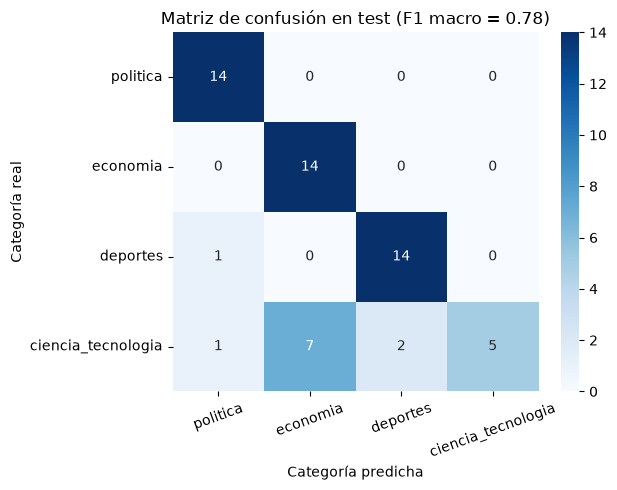

In [15]:
cm = confusion_matrix(test["etiqueta"], test["pred_ft"], labels=ETIQUETAS)
plt.figure(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ETIQUETAS, yticklabels=ETIQUETAS)
plt.xlabel("Categoría predicha"); plt.ylabel("Categoría real")
plt.title(f"Matriz de confusión en test (F1 macro = {res_ft['f1_macro']:.2f})")
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig("modelo/matriz_confusion.png", dpi=150)
plt.show()

In [16]:
# Ayuda para la reflexión: F1 por categoría, confusiones más frecuentes y errores concretos.
f1_cat = pd.Series(f1_score(test["etiqueta"], test["pred_ft"], labels=ETIQUETAS, average=None), index=ETIQUETAS).round(3)
print("F1 por categoría:\n", f1_cat.sort_values(), "\n")
errores = test[test["etiqueta"] != test["pred_ft"]]
print("Confusiones más frecuentes (real -> predicha):")
print(errores.groupby(["etiqueta", "pred_ft"]).size().sort_values(ascending=False).head(5).to_string(), "\n")
errores[["titular", "etiqueta", "pred_ft", "prob_ft"]].head(10)

F1 por categoría:
 ciencia_tecnologia    0.500
economia              0.800
deportes              0.903
politica              0.933
dtype: float64 

Confusiones más frecuentes (real -> predicha):
etiqueta            pred_ft 
ciencia_tecnologia  economia    7
                    deportes    2
                    politica    1
deportes            politica    1 



,titular,etiqueta,pred_ft,prob_ft
2,Finlandia frena la construcción de dos centros...,ciencia_tecnologia,economia,0.599453
5,Trump quiere llamar “superinteligencia” a la I...,ciencia_tecnologia,politica,0.423672
9,Mourinho sorprende con mensaje sobre Vinícius:...,deportes,politica,0.587295
18,El Niño alcanza niveles récord en el Pacífico ...,ciencia_tecnologia,economia,0.512252
21,Meta afirma que unos ‘hackers’ accedieron a su...,ciencia_tecnologia,economia,0.423754
22,Estafas digitales contra adultos mayores: seis...,ciencia_tecnologia,economia,0.444621
33,Perú: más de 200 operativos en el año en Madre...,ciencia_tecnologia,economia,0.713796
36,"Francis Halzen, el nuevo premio nobel de Físic...",ciencia_tecnologia,deportes,0.319395
38,“Ace Combat 8: Wings of Theve” eleva la franqu...,ciencia_tecnologia,deportes,0.361737
41,Informe Planeta Vivo 2026: la fauna silvestre ...,ciencia_tecnologia,economia,0.705231


**Reflexión por categoría (escríbela con TUS números de arriba, 5–8 líneas):**
- ¿Qué categoría tuvo mejor F1 y por qué crees que es más fácil (vocabulario propio)?
- ¿Cuál fue la peor y con cuál se confundió? Cita 1–2 titulares concretos mal clasificados.
- ¿El problema es del modelo, de los datos (pocos ejemplos, etiquetas por sección que a veces no reflejan el tema) o de la ambigüedad real del titular?
- ¿Qué harías para mejorar: más datos, otro modelo (BETO), más épocas, limpiar etiquetas?

**Política (F1 0.93), deportes (0.90) y economía (0.80)** tienen recall de 0.93 a 1.00: el modelo las reconoce casi siempre. **La excepción es ciencia y tecnología:** F1 0.50, precisión 1.00 y recall 0.33 (5 de 15). De sus 10 errores, 7 se clasificaron como economía, 2 como deportes y 1 como política.

El modelo es cauteloso con esta categoría (cuando la predice, acierta) pero deja escapar dos de cada tres casos. La razón probable es que es muy heterogénea: mezcla IA, ciberseguridad, ambiente, ciencia y videojuegos (El Niño, Informe Planeta Vivo, Meta, el Nobel de Física, Ace Combat), con pocos ejemplos de entrenamiento (269 en total). La auditoría muestra otro factor: los titulares de tecnología se cruzan con economía (Rextie, Interseguro) y con política (Finlandia y Google). Economía queda con precisión 0.667 porque absorbe esos casos. Mejoras posibles: más ejemplos de ciencia y tecnología o redefinir la categoría.

## 7. Comparación y justificación

La tabla compara los tres enfoques. Zero-shot y fine-tuning se miden también sobre **los mismos 40 titulares** para que la comparación sea justa.

In [17]:
idx40 = test["titular"].isin(muestra40["titular"])
res_ft_40 = metricas(test.loc[idx40, "y"], test.loc[idx40, "pred_ft"].map(LABEL2ID))

tabla = pd.DataFrame({
    "Enfoque": ["Zero-shot (xlm-roberta-large-xnli)", "Fine-tuning (distilbert multilingüe)", "LLM (Gemini)"],
    "Titulares evaluados": [40, f"{len(test)} (y 40 comparables)", len(en_test)],
    "Accuracy": [res_zs["accuracy"], res_ft["accuracy"], res_llm_test["accuracy"]],
    "F1 macro": [res_zs["f1_macro"], res_ft["f1_macro"], res_llm_test["f1_macro"]],
    "F1 macro en los 40": [res_zs["f1_macro"], res_ft_40["f1_macro"], np.nan],
    "Tiempo": [f"{tiempo_zs:.0f} s (inferencia)", f"{tiempo_ft:.0f} s (entrenar)", "~1–2 min (API)"],
    "Costo": ["gratis", "gratis (GPU Colab)", "gratis (cuota) / pago por token"],
}).round(3)
tabla

,Enfoque,Titulares evaluados,Accuracy,F1 macro,F1 macro en los 40,Tiempo,Costo
0,Zero-shot (xlm-roberta-large-xnli),40,0.825,0.820,0.820,23 s (inferencia),gratis
1,Fine-tuning (distilbert multilingüe),58 (y 40 comparables),0.810,0.784,0.789,79 s (entrenar),gratis (GPU Colab)
2,LLM (Gemini),58,0.914,0.913,NaN,~1–2 min (API),gratis (cuota) / pago por token


**Justificación (escríbela tú, 6–8 líneas).** Responde con los números de la tabla:
- ¿Cuál enfoque elegirías para producción y por qué? Considera: calidad (F1 macro), velocidad al predecir, costo, y necesidad de datos etiquetados.
- ¿Cuánto ganó el fine-tuning respecto al zero-shot? ¿Justifica el esfuerzo de etiquetar y entrenar?
- ¿Qué ventaja tiene el LLM (no requiere entrenar) y qué riesgos (costo por uso, dependencia de una API, falta de control)?
- Limitaciones de tu estudio: una sola fuente (El Comercio), ~385 titulares, 4 categorías, etiquetas basadas en la sección del medio.

**Elijo el modelo con fine-tuning (DistilBERT multilingüe) para el dashboard**, aunque el zero-shot tuvo un F1 macro algo mayor (0.82 frente a 0.78).

1. **La diferencia no es concluyente:** se midieron en conjuntos distintos (40 y 58 titulares) y un solo error mueve la accuracy 1.7 puntos.
2. **Costo de uso:** el zero-shot usa `xlm-roberta-large` (unos 560 millones de parámetros), lento y con mucha memoria; DistilBERT (unos 135 millones) responde rápido y cabe en un dashboard gratuito.
3. **Margen de mejora:** su debilidad se concentra en una categoría y se puede atacar con más datos; el zero-shot no mejora con datos.
4. **Papel de los otros enfoques:** el zero-shot es útil como línea base cuando no hay etiquetas, y el etiquetado con LLM sirve para contrastar las etiquetas, pero su acuerdo del 80 % conmigo muestra que no es una verdad absoluta.

Si solo importara el F1 con estos datos, ganaría el zero-shot por poco; el criterio de despliegue inclina la decisión hacia el fine-tuning.

## 8. Guardar resultados (archivos livianos)

Los **pesos del modelo pesan ~500 MB**: GitHub rechaza archivos de más de 100 MB, así que **no se suben al repositorio** (`.gitignore` ya bloquea `*.safetensors` y `*.bin`). Subimos solo métricas, mapa de etiquetas, imagen de la matriz y predicciones; los pesos se publican en Hugging Face Hub (gratis) para que el dashboard de la Parte 3 los descargue.

In [18]:
metricas_finales = {
    "f1_macro_test": round(res_ft["f1_macro"], 4), "accuracy_test": round(res_ft["accuracy"], 4),
    "zero_shot_accuracy_40": round(res_zs["accuracy"], 4), "zero_shot_f1_macro_40": round(res_zs["f1_macro"], 4),
    "acuerdo_llm_humano_de_20": acuerdo_20, "acuerdo_llm_vs_seccion": round(float(acuerdo_total), 4),
    "modelo_base": NOMBRE_MODELO, "modelo_llm": MODELO_LLM, "n_train": len(train), "n_val": len(val), "n_test": len(test),
}
json.dump(metricas_finales, open("modelo/metricas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
json.dump({"id2label": ID2LABEL, "label2id": LABEL2ID}, open("modelo/etiquetas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
test[["titular", "medio", "etiqueta", "pred_ft", "prob_ft"]].to_csv("datos/predicciones_test.csv", index=False)
print(json.dumps(metricas_finales, ensure_ascii=False, indent=2))

{
  "f1_macro_test": 0.7841,
  "accuracy_test": 0.8103,
  "zero_shot_accuracy_40": 0.825,
  "zero_shot_f1_macro_40": 0.8202,
  "acuerdo_llm_humano_de_20": 16,
  "acuerdo_llm_vs_seccion": 0.9195,
  "modelo_base": "distilbert-base-multilingual-cased",
  "modelo_llm": "gemini-3.5-flash-lite",
  "n_train": 269,
  "n_val": 58,
  "n_test": 58
}


In [19]:
# OPCIONAL: publicar el modelo en Hugging Face Hub (necesita el secreto HF_TOKEN con permiso de escritura).
SUBIR_A_HF = False
REPO_HF = "gabriela-pozo/noticias-pe-distilbert"   # cambia el usuario si hace falta

if SUBIR_A_HF:
    from huggingface_hub import login
    login(leer_secreto("HF_TOKEN"))
    entrenador.model.push_to_hub(REPO_HF)
    tokenizador.push_to_hub(REPO_HF)
    print("Modelo publicado en https://huggingface.co/" + REPO_HF)

In [20]:
# Línea para el comentario de entrega en el Issue #188:
n = metricas_finales
print(f"Resultados Test: F1 Macro {n['f1_macro_test']:.2f} | Zero-shot {n['zero_shot_accuracy_40']:.2f} (accuracy en 40) | "
      f"Acuerdo LLM-Humano {n['acuerdo_llm_humano_de_20']}/20")

Resultados Test: F1 Macro 0.78 | Zero-shot 0.82 (accuracy en 40) | Acuerdo LLM-Humano 16/20


In [21]:
# Descarga los archivos livianos para subirlos al repositorio (solo funciona en Colab).
try:
    from google.colab import files
    for ruta in ["datos/etiquetas_llm.csv", "datos/split.csv", "datos/predicciones_test.csv",
                 "modelo/metricas.json", "modelo/etiquetas.json", "modelo/matriz_confusion.png"]:
        files.download(ruta)
except ImportError:
    print("No estás en Colab: los archivos ya están en tu carpeta.")

No estás en Colab: los archivos ya están en tu carpeta.
